# 7주차 실습 - 데이터 시각화와 EDA

**데이터과학과 인공지능 · 2026-2학기**

슬라이도 링크: https://app.sli.do/event/aceabMKfUvE9K1mZLUitKt

---

### 오늘의 목표

- **EDA**(탐색적 데이터 분석)가 무엇이고 어떤 순서로 하는지 안다
- **변수 종류에 따라 그래프를 고를** 수 있다
- 분포·관계·그룹 차이를 그림으로 확인한다
- 그래프에서 **이상치**를 발견하고, 그것이 결과를 어떻게 바꾸는지 확인한다

### 오늘 쓰는 지난주 도구들

| 배운 것 | 오늘 이렇게 활용하게 됩니다 |
|---|---|
| `df["열"]`, `df[조건]` | 그릴 데이터를 고를 때 |
| `groupby()` | 그룹별로 묶어서 그릴 때 |
| `describe()` | 그래프와 숫자를 대조할 때 |
| `.str.contains()` | 후기에서 키워드를 찾을 때 |
| 점 표기법 `.무엇()` | 오늘 배울 `.plot()` 이 바로 이것 |



---
## 0. 준비 — 한글 폰트와 데이터

### 0.1. 한글이 깨지지 않게 하기

matplotlib(그림 그리는 도구)는 **기본 설정에서 한글을 못 읽습니다.** 그냥 그리면 글자가 전부 네모(□□□)로 나옵니다.

아래 셀을 **먼저 실행**하세요. 한 번만 하면 됩니다.

In [1]:
!pip install -q koreanize-matplotlib

import koreanize_matplotlib      # 이 한 줄이 한글 폰트를 설정해 줍니다
import matplotlib.pyplot as plt
import pandas as pd

print("한글폰트 설정 완료")

한글폰트 설정 완료


`!pip install` 은 **새 도구를 설치**하는 명령입니다. 앞에 느낌표가 붙은 건 "Python 코드가 아니라 설치 명령"이라는 표시입니다.

`import matplotlib.pyplot as plt` 4주차에 배운 `import ... as ...` 입니다. 그림 그리는 도구를 `plt` 라는 별명으로 가져옵니다.

> **네모(□□□)가 보인다면** 런타임을 재시작하세요. **런타임 → 세션 다시 시작** 후 이 셀부터 다시 실행하면 해결됩니다.

### 0.2. 오늘의 데이터

8주치로 늘어난 카페 데이터입니다. **기온** 열이 새로 생겼습니다.

In [2]:
# ❗ 설정 셀 — 그냥 실행하세요
import random
random.seed(77)

메뉴정보 = {
    "아메리카노": ("커피", 4500), "카페라떼": ("커피", 5000),
    "바닐라라떼": ("커피", 5500), "콜드브루": ("커피", 5000),
    "녹차라떼": ("논커피", 5500), "초코라떼": ("논커피", 5500),
    "자몽에이드": ("논커피", 6000), "복숭아아이스티": ("논커피", 4500),
}
요일표 = ["월", "화", "수", "목", "금"]
요일효과 = {"월": -3, "화": -2, "수": 0, "목": 2, "금": 6}

좋은후기 = ["맛이 깔끔하고 좋았어요", "직원분이 친절하셨습니다", "자리가 넓어서 공부하기 좋아요",
          "가격 대비 양이 넉넉합니다", "향이 진하고 맛있어요", "분위기가 조용해서 좋네요"]
보통후기 = ["무난한 맛입니다", "그냥 평범했어요", "가격은 적당한 편", "다시 올지는 모르겠네요"]
나쁜후기 = ["대기 시간이 너무 길었어요", "자리가 없어서 서서 마셨어요", "주문이 잘못 나왔어요",
          "너무 붐벼서 정신없었어요", "맛이 생각보다 밍밍합니다"]

# 2026-03-02(월) ~ 2026-04-24(금), 평일 40일
달일수 = {3: 31, 4: 30}
날짜들 = []
월, 일 = 3, 2
while len(날짜들) < 40:
    주차인덱스 = len(날짜들) % 5
    날짜들.append((월, 일, 요일표[주차인덱스]))
    일 += 3 if 주차인덱스 == 4 else 1      # 금요일 다음은 월요일
    if 일 > 달일수[월]:
        일 -= 달일수[월]
        월 += 1

행들 = ["날짜,요일,기온,매장,메뉴,분류,가격,수량,결제수단,평점,후기"]
for 차례, (월, 일, 요일) in enumerate(날짜들):
    날짜 = f"2026-{월:02d}-{일:02d}"
    기온 = round(7 + (차례 / 39) * 11 + random.gauss(0, 2.2), 1)
    for 매장 in ["안암점", "정문점"]:
        매장효과 = 3 if 매장 == "안암점" else 0
        for 메뉴 in random.sample(list(메뉴정보), 3):
            분류, 가격 = 메뉴정보[메뉴]
            기온효과 = (기온 - 12) * (1.9 if 분류 == "논커피" else -0.7)
            수량 = 24 + 기온효과 + 요일효과[요일] + 매장효과 + random.gauss(0, 4)
            수량 = max(4, round(수량))
            결제 = random.choice(["카드", "현금", "간편결제"])
            # 붐비는 날일수록 불만이 늘어납니다
            불만가중 = min(30, max(0, 수량 - 28))
            평점 = random.choices([1, 2, 3, 4, 5],
                                weights=[2 + 불만가중 * 0.5, 5 + 불만가중 * 0.8,
                                         18 + 불만가중 * 0.4, 40, 30])[0]
            후기 = random.choice(좋은후기 if 평점 >= 4 else (보통후기 if 평점 == 3 else 나쁜후기))
            행들.append(f"{날짜},{요일},{기온},{매장},{메뉴},{분류},{가격},{수량},{결제},{평점},{후기}")

# 단체 주문 2건 — 나중에 박스플롯에서 다시 만나게 됩니다
행들.append("2026-04-10,금,17.2,안암점,아메리카노,커피,4500,168,카드,4,맛이 깔끔하고 좋았어요")
행들.append("2026-03-27,금,13.8,정문점,카페라떼,커피,5000,140,간편결제,3,무난한 맛입니다")

with open("cafe_sales_8weeks.csv", "w", encoding="utf-8") as f:
    f.write("\n".join(행들))

print(f"cafe_sales_8weeks.csv 생성 완료 — 총 {len(행들) - 1}행")

cafe_sales_8weeks.csv 생성 완료 — 총 242행


In [3]:
df = pd.read_csv("cafe_sales_8weeks.csv")
df["날짜"] = pd.to_datetime(df["날짜"])
df["매출"] = df["가격"] * df["수량"]

# 요일은 "순서가 있는 범주"라고 Pandas에게 알려줍니다
df["요일"] = pd.Categorical(df["요일"], categories=["월", "화", "수", "목", "금"], ordered=True)

print(df.shape)
df.head()

(242, 12)


,날짜,요일,기온,매장,메뉴,분류,가격,수량,결제수단,평점,후기,매출
0,2026-03-02,월,7.6,안암점,콜드브루,커피,5000,24,현금,4,향이 진하고 맛있어요,120000
1,2026-03-02,월,7.6,안암점,카페라떼,커피,5000,30,간편결제,4,향이 진하고 맛있어요,150000
2,2026-03-02,월,7.6,안암점,아메리카노,커피,4500,27,카드,5,맛이 깔끔하고 좋았어요,121500
3,2026-03-02,월,7.6,정문점,복숭아아이스티,논커피,4500,5,카드,4,맛이 깔끔하고 좋았어요,22500
4,2026-03-02,월,7.6,정문점,카페라떼,커피,5000,24,카드,4,자리가 넓어서 공부하기 좋아요,120000


5주차 3.3절에서 **순서형** 변수를 배웠습니다. 요일이 딱 그렇습니다. 월·화·수·목·금에는 **정해진 순서**가 있죠.

그런데 Pandas는 그걸 모릅니다. 그냥 글자로 보고 **가나다순으로 정렬**해 버립니다. 그러면 그래프가 `금, 목, 수, 월, 화` 순서로 나옵니다. 읽을 수가 없습니다.

`pd.Categorical(..., ordered=True)` 가 **"이 열은 이 순서를 가진 범주다"** 라고 알려주는 명령입니다. 한 번 지정해 두면 이후 모든 그래프와 `groupby` 가 그 순서를 따릅니다.

> 학년(1·2·3·4), 등급(상·중·하), 분기(1Q-4Q), 리커트 척도(매우 불만-매우 만족) 전부 순서형입니다. 지정하지 않으면 그래프가 엉뚱한 순서로 나옵니다.

6주차에 배운 `to_datetime()` 과 파생 열 만들기를 바로 써보았습니다.

데이터 설명서는 5주차와 같되 두 가지가 다릅니다.

> - **기간**: 2026년 3월 2일 ~ 4월 24일 (평일 40일)
> - **기온**: 그날 낮 최고기온(℃)
>
> 기온은 **카페가 수집한 게 아니라 다른 출처에서 가져와 붙인 값**입니다. 이렇게 서로 다른 출처의 데이터를 합치는 일은 아주 흔한데, **단위와 기준이 맞는지** 꼭 확인해야 합니다. 여기서는 "같은 날짜"로 붙였습니다.

---
## 1. EDA란 무엇인가

**EDA**(Exploratory Data Analysis, 탐색적 데이터 분석)는 말 그대로 **데이터를 둘러보는 일**입니다.

가설을 세워놓고 검증하는 게 아니라, **"이 데이터에 뭐가 들어 있지?"** 하고 살펴보면서 질문을 찾아가는 과정입니다.

### 왜 그림을 그려야할까

숫자만 봐서는 안 보이는 게 있기 때문입니다. 아래를 보세요.

In [4]:
print(df.groupby("분류")["수량"].describe().round(1))

     count  mean   std   min   25%   50%   75%    max
분류                                                   
논커피  129.0  26.3  10.4   5.0  19.0  27.0  33.0   58.0
커피   113.0  28.4  18.0  10.0  23.0  27.0  30.0  168.0


커피와 논커피의 평균이 비슷하게 나옵니다. 그러면 **두 분류가 비슷하게 팔린다**고 결론 내도 될까요?


### EDA의 순서

정해진 법은 없지만, 대체로 이러한 순서를 따릅니다.

| 단계 | 하는 일 | 오늘의 진도 |
|---|---|---|
| ① 한 변수씩 보기 | 각 열이 어떻게 생겼나 (분포) | 3~4절 |
| ② 두 변수 묶어 보기 | 변수끼리 관계가 있나 | 5절 |
| ③ 그룹으로 나눠 보기 | 집단 간 차이가 있나 | 6절 |
| ④ 시간 따라 보기 | 시간이 지나며 변했나 | 7절 |
| ⑤ 이상한 것 쫓아가기 | 눈에 띄는 게 왜 그런지 | 내내 |

**⑤번이 중요합니다.** EDA는 한 번에 끝나는 절차가 아니라, 그래프를 보고 → 이상한 걸 발견하고 → 다시 그려보는 **반복**입니다.

> ### EDA를 하는 태도
>
> EDA의 목적은 **"내 생각이 맞았다"는 증거를 찾는 것이 아닙니다.** 오히려 그 반대입니다. 내가 놓친 것, 생각과 다른 것을 찾아내려고 보는 것입니다.
>
> 그래서 EDA를 할 때는 **예쁜 그래프보다 이상한 그래프가 더 반가워야 하(지만 그렇게 반갑지는 않은)압니다.**

---
## 2. 그래프 고르기 - 변수 종류와 짝 맞추기

어떤 그래프를 그릴지는 취향이 아니라 **변수의 종류**가 정합니다.

5주차 3.3절에서 배운 변수 종류를 다시 가져와봅시다.

| 변수 종류 | 예 (우리 데이터) |
|---|---|
| **명목형** (범주) | 매장, 메뉴, 분류, 결제수단 |
| **순서형** | 평점 |
| **이산형** | 수량 |
| **연속형** | 기온, 매출 |

이제 짝을 맞춰 봅시다.

### 변수 하나를 볼 때

| 변수 종류 | 그래프 | `kind=` |
|---|---|---|
| 명목형·순서형 | **막대그래프** | `"bar"` |
| 이산형·연속형 | **히스토그램** | `"hist"` |
| 이산형·연속형 (퍼짐·이상치) | **박스플롯** | `"box"` |

### 변수 둘을 볼 때

| 조합 | 그래프 | `kind=` |
|---|---|---|
| 연속형 ↔ 연속형 | **산점도** | `"scatter"` |
| 명목형 ↔ 연속형 | **그룹별 막대** 또는 **박스플롯** | `"bar"` / `"box"` |
| 시간 ↔ 연속형 | **선그래프** | `"line"` |

> **막대그래프와 히스토그램은 다릅니다.**
>
> 막대그래프는 **범주별 개수나 값**을 보여줍니다. 막대 사이가 떨어져 있습니다.
> 히스토그램은 **숫자를 구간으로 나눠 센 것**입니다. 막대가 붙어 있습니다. 구간이 이어져 있기 때문입니다.
>
> 범주에 히스토그램을 그리거나 숫자에 막대그래프를 그리면 읽을 수 없는 그림이 나옵니다.

---
## 3. 한 변수 보기 - 분포

### 3.1. 히스토그램 - 숫자가 어떻게 퍼져 있나

Pandas는 `.plot()` 메서드를 가지고 있습니다. **점 표기법 그대로**입니다.

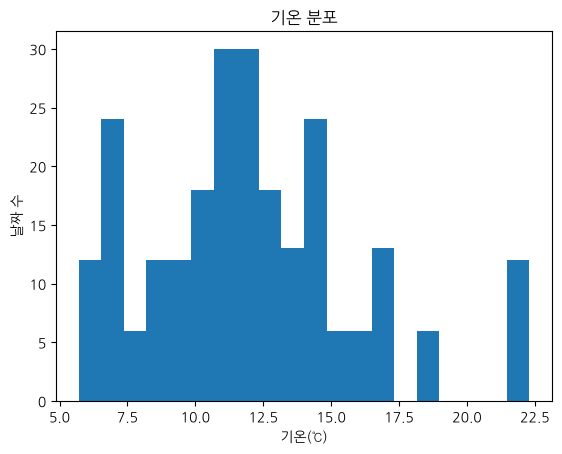

In [5]:
df["기온"].plot(kind="hist", bins=20, title="기온 분포")
plt.xlabel("기온(℃)")
plt.ylabel("날짜 수")
plt.show()

읽는 방법은 이렇습니다.

```
df["기온"].plot(kind="hist", bins=20)
└─┬─┘ └────┬─────┘
  이 열을    히스토그램으로 그려줘
```

- `kind=` : 어떤 그래프인지
- `bins=` : 구간을 몇 개로 나눌지 (많을수록 잘게)
- `plt.xlabel()`, `plt.ylabel()` : 가로축·세로축 이름. **안 쓰면 세로축이 `Frequency` 라고 영어로 나옵니다**
- `plt.show()` : **그림을 화면에 띄워달라**  

`bins` 를 바꾸면 그림이 달라집니다. 직접 비교해 보세요.

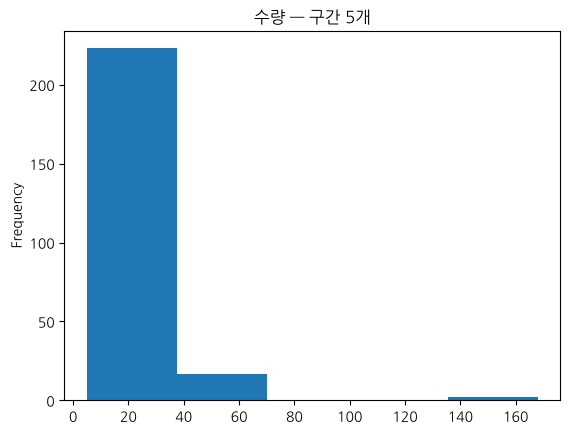

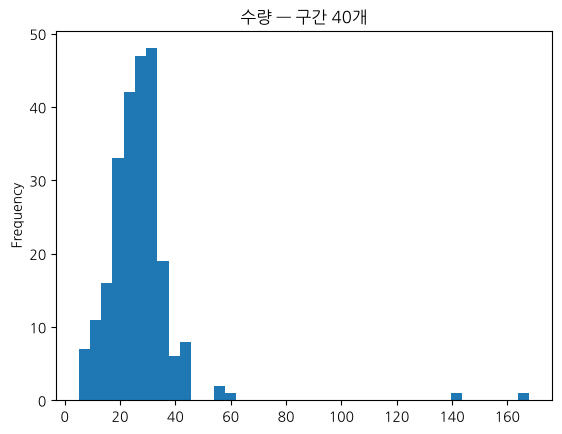

In [6]:
df["수량"].plot(kind="hist", bins=5, title="수량 — 구간 5개")
plt.show()

df["수량"].plot(kind="hist", bins=40, title="수량 — 구간 40개")
plt.show()

**같은 데이터인데 인상이 다릅니다.** 구간을 적게 잡으면 뭉뚱그려지고, 많이 잡으면 들쭉날쭉해 보입니다.

`bins` 에 정답은 없습니다. 다만 **보고서에 넣을 때는 몇 개로 나눴는지 밝히는 게** 좋습니다.

구간 40개짜리 그림에서 **오른쪽 끝에 외톨이 막대**가 보이나요?

### 3.2. 막대그래프 — 범주별 개수

범주형은 `value_counts()` 로 센 다음 막대로 그립니다. 5주차에 배운 것을 기억해봅시다.

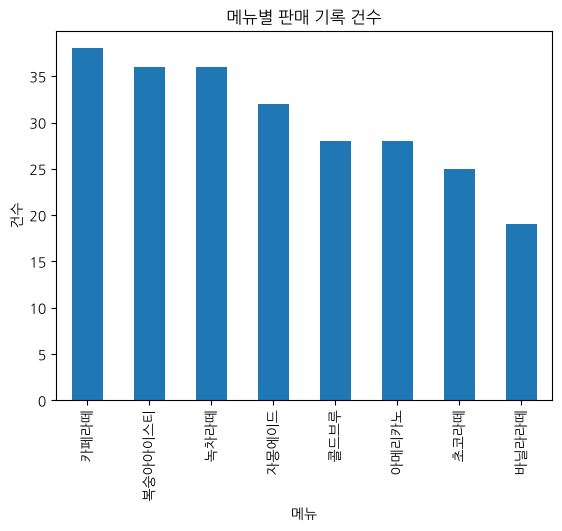

In [7]:
df["메뉴"].value_counts().plot(kind="bar", title="메뉴별 판매 기록 건수")
plt.ylabel("건수")
plt.show()

`value_counts()` 의 결과(Series)에 `.plot()` 을 이어 붙였습니다. **점이 연달아 나오는 구조**(5주차 3.2절)입니다.

메뉴 이름이 **세로로 누워있어** 읽기 불편합니다. 항목 이름이 길 때는 **가로 막대**가 낫습니다. `kind="barh"` 입니다.

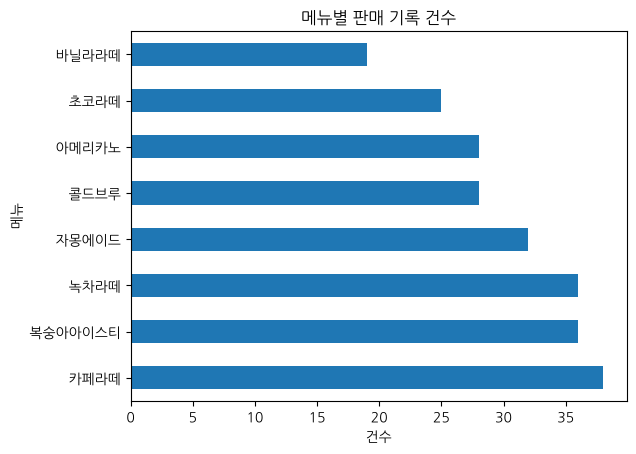

In [8]:
df["메뉴"].value_counts().plot(kind="barh", title="메뉴별 판매 기록 건수")
plt.xlabel("건수")
plt.show()

### ⏸ 직접 해보세요 (1)

1. `매출` 의 히스토그램을 그리세요 (구간 30개)
2. `결제수단` 의 막대그래프를 그리세요
3. `평점` 은 어떤 그래프가 맞을까요? 2절 표를 보고 골라서 그려보세요

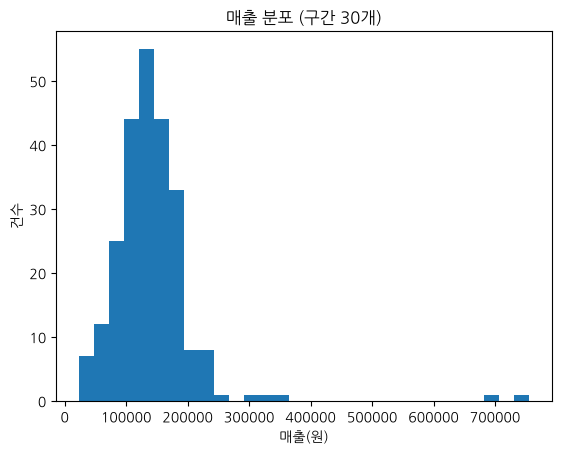

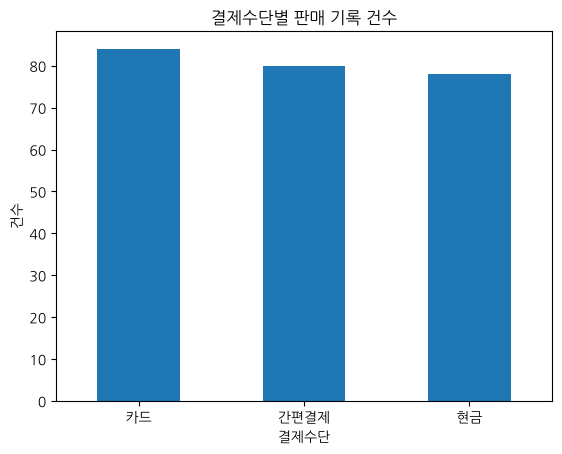

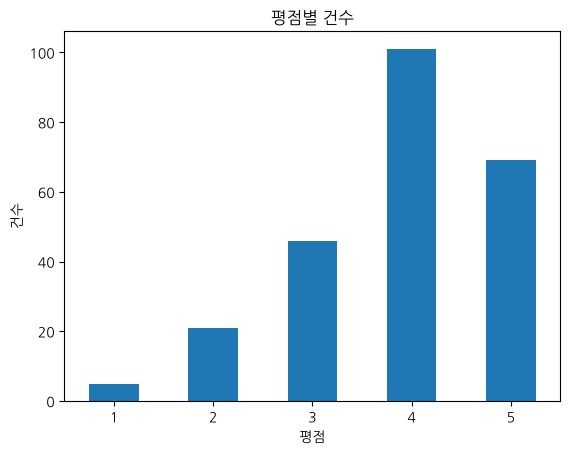

In [9]:
# TODO 1. 매출 히스토그램 (구간 30개)
df["매출"].plot(kind="hist", bins=30, title="매출 분포 (구간 30개)")
plt.xlabel("매출(원)")
plt.ylabel("건수")
plt.show()

# TODO 2. 결제수단 막대그래프 (명목형 → 막대)
df["결제수단"].value_counts().plot(kind="bar", title="결제수단별 판매 기록 건수")
plt.ylabel("건수")
plt.xticks(rotation=0)
plt.show()

# TODO 3. 평점은 순서형 → 막대그래프 (sort_index()로 1~5점 순서대로)
df["평점"].value_counts().sort_index().plot(kind="bar", title="평점별 건수")
plt.xlabel("평점")
plt.ylabel("건수")
plt.xticks(rotation=0)
plt.show()


---
## 4. 박스플롯과 이상치

### 4.1. 박스플롯 읽는 법

**박스플롯**은 6주차에 본 `describe()` 를 그림으로 옮긴 것입니다.

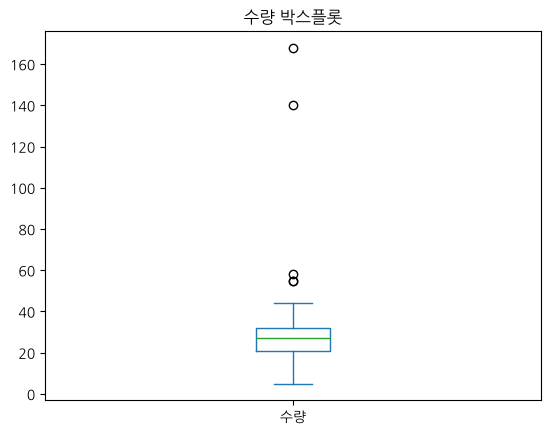

In [10]:
df["수량"].plot(kind="box", title="수량 박스플롯")
plt.show()

```
   ○  ← 이상치 (수염 밖의 점)
   ○
   │
  ┬┴┬  ← 수염 끝 (대략 가장 큰 보통 값)
  │ │
  ├─┤  ← 상자 위 = 75% 지점
  ├━┤  ← 가운데 굵은 선 = 중앙값(50%)
  ├─┤  ← 상자 아래 = 25% 지점
  │ │
  ┴┬┴  ← 수염 끝
```

- **상자**에 전체의 가운데 절반(25%~75%)이 들어 있습니다
- **굵은 선**이 중앙값입니다. 평균이 아닙니다
- **점**으로 따로 찍힌 것이 **이상치 후보**입니다

### 4.2. 이상치를 쫓아가기

위 그림에 점이 몇 개 보입니다. **무엇인지 확인해야 합니다.**

6주차에 배운 조건 필터링으로 찾아봅시다.

In [11]:
df[df["수량"] > 100][["날짜", "매장", "메뉴", "수량", "결제수단"]]

,날짜,매장,메뉴,수량,결제수단
240,2026-04-10,안암점,아메리카노,168,카드
241,2026-03-27,정문점,카페라떼,140,간편결제


수량이 100잔을 넘는 기록이 두 건 나왔습니다. 평소 20~30잔인데 **168잔, 140잔**입니다.

### 4.3. 전산 오류인가, 사실인가

판단이 필요합니다. 6주차 결측치 때와 같은 상황입니다.

**오류일 가능성** — 입력 실수(16.8을 168로), 단위 착오

**사실일 가능성** — 단체 주문, 행사, 기업 납품

우리 데이터는 둘 다 **금요일**이고 **결제수단이 기록되어 있으며** 평점·후기도 정상입니다. 입력 오류라기보다 **단체 주문**으로 보는 게 자연스럽습니다.

> ### 이상치를 지워야 할까요?
>
> **아니요.**
>
> 이상치는 **버려야 할 오염이 아니라 흥미로운 단서**인 경우가 많습니다. 신용카드 부정사용 탐지, 의료 이상 징후, 설비 고장 예측 등이 전부 이상치를 찾는 일입니다.
>
> 지워도 되는 건 **명백한 오류**일 때뿐입니다. 그리고 지웠다면 **몇 건을 왜 지웠는지 반드시 밝혀야** 합니다.
>
> 오늘은 "단체 주문은 일상적인 판매 패턴과 성격이 다르다"는 이유로 **분석에서 따로 떼어** 보겠습니다. 지우는 게 아니라 **나눠서 보는 것**입니다.

In [12]:
일반 = df[df["수량"] < 100]      # 일상 판매
단체 = df[df["수량"] >= 100]     # 단체 주문

print("일반:", len(일반), "건")
print("단체:", len(단체), "건")

일반: 240 건
단체: 2 건


### 4.4. 그룹별 박스플롯

박스플롯의 진짜 쓸모는 **여러 집단을 나란히 놓고 비교**할 때 나옵니다.

`by=` 로 묶을 기준을 줍니다.

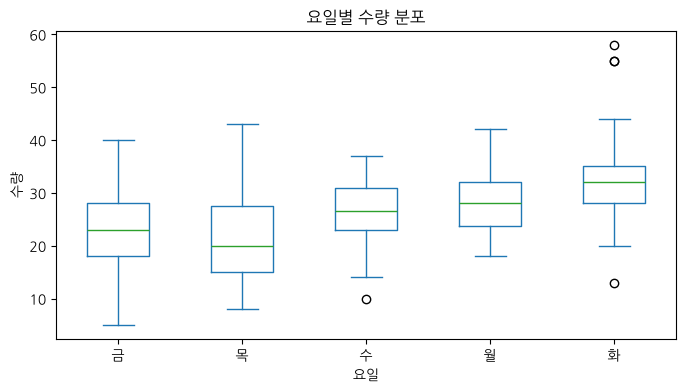

In [13]:
일반.plot(kind="box", column="수량", by="요일", figsize=(8, 4))
plt.suptitle("")                       # 자동으로 붙는 제목을 지웁니다
plt.title("요일별 수량 분포")
plt.xlabel("요일")
plt.ylabel("수량")
plt.xticks(rotation=0)
plt.show()

0.2절에서 요일을 순서형으로 지정해 둔 덕분에 **월~금 순서로** 나왔습니다. 지정하지 않았다면 금·목·수·월·화 순이었을 겁니다.

월요일에서 금요일로 갈수록 상자가 **위로 올라갑니다.** 평균만 봤을 때보다 훨씬 많은 정보가 보입니다. 각 요일의 **퍼짐 정도**까지 같이 보이기 때문입니다.

### ⏸ 직접 해보세요 (2)

1. `일반` 데이터로 **매장별** 수량 박스플롯을 그리세요
2. `일반` 데이터로 **분류별**(커피/논커피) 수량 박스플롯을 그리세요
3. 2번 그림을 보고, 1절에서 본 `describe()` 결과와 **다르게 보이는 점**이 있나요? 주석에 한 줄 적어보세요

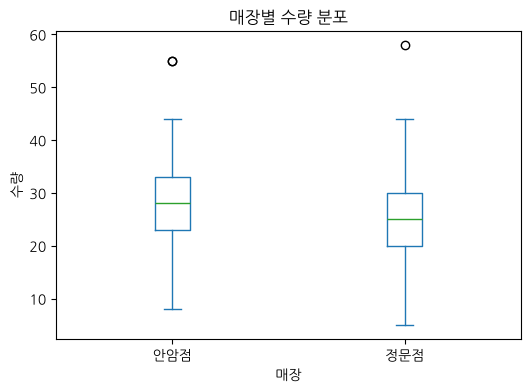

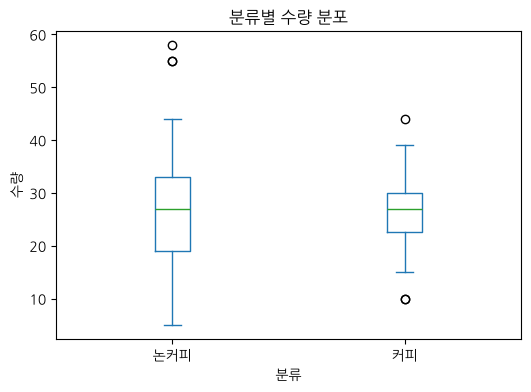

In [14]:
# TODO 1. 매장별 수량 박스플롯 (일반 데이터)
일반.plot(kind="box", column="수량", by="매장", figsize=(6, 4))
plt.suptitle("")
plt.title("매장별 수량 분포")
plt.xlabel("매장")
plt.ylabel("수량")
plt.show()

# TODO 2. 분류별 수량 박스플롯 (일반 데이터)
일반.plot(kind="box", column="수량", by="분류", figsize=(6, 4))
plt.suptitle("")
plt.title("분류별 수량 분포")
plt.xlabel("분류")
plt.ylabel("수량")
plt.show()

# 3. 답: 1절 describe()에서는 평균이 논커피 26.3, 커피 28.4로 비슷해 보였고(커피는 단체 주문 168잔 때문에 평균이 올라가 있음),
#    일반 데이터 박스플롯에서는 평균이 거의 같아도(26.3 vs 26.1) 논커피의 상자와 수염이 훨씬 길다(표준편차 10.4 vs 5.9). 평균에 가려진 퍼짐 차이가 보인다.


---
## 5. 두 변수 보기 — 산점도

### 5.1. 산점도 그리기

**산점도**는 점 하나가 행 하나입니다. 가로축과 세로축에 각각 다른 변수를 놓습니다.

연속형 둘의 관계를 볼 때 씁니다. 기온과 수량을 봅시다.

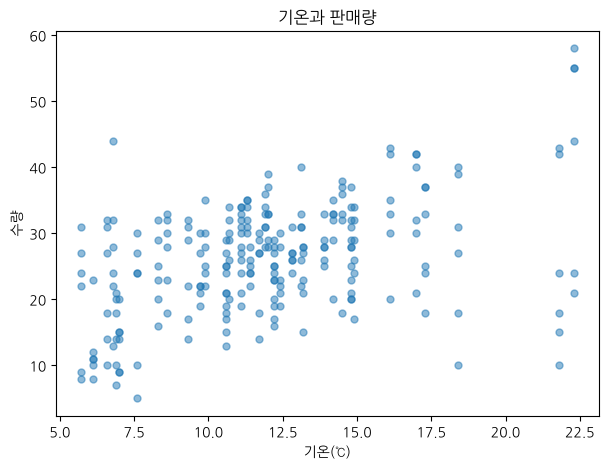

In [15]:
일반.plot(kind="scatter", x="기온", y="수량", alpha=0.5, s=25, figsize=(7, 5),
         title="기온과 판매량")
plt.xlabel("기온(℃)"); plt.ylabel("수량")
plt.show()

`x=`, `y=` 로 두 축에 올릴 열을 지정합니다. `alpha=0.5` 는 **점을 반투명하게**, `s=25` 는 **점 크기**를 정하는 설정입니다. 점이 겹쳐 있을 때 얼마나 몰려 있는지 보입니다.

뭔가 보이긴 하는데 뚜렷하지 않습니다. **흩어진 두 덩어리** 같습니다.

### 5.2. 나눠서 그려보기

두 덩어리라면 **뭔가로 나뉘어 있다**는 뜻입니다. 분류별로 따로 그려봅시다.

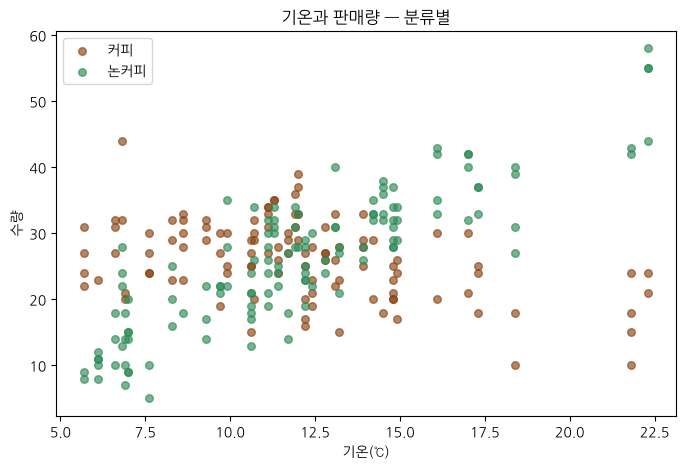

In [16]:
커피 = 일반[일반["분류"] == "커피"]
논커피 = 일반[일반["분류"] == "논커피"]

그림 = 커피.plot(kind="scatter", x="기온", y="수량", alpha=0.65, s=30,
              color="saddlebrown", label="커피", figsize=(8, 5))
논커피.plot(kind="scatter", x="기온", y="수량", alpha=0.65, s=30,
          color="seagreen", label="논커피", ax=그림)

plt.title("기온과 판매량 — 분류별")
plt.xlabel("기온(℃)"); plt.ylabel("수량")
plt.legend()
plt.show()

**완전히 다른 그림이 나왔습니다.**

- **논커피**(초록)는 기온이 오를수록 뚜렷하게 **올라갑니다**
- **커피**(갈색)는 기온이 올라도 거의 변화가 없거나 살짝 **내려갑니다**

1절에서 평균만 봤을 때는 "둘이 비슷하다"고 보였습니다. **그림을 그리니 정반대 이야기가 나왔습니다.** 이게 EDA를 하는 이유입니다.

새로 나온 것 두 가지만 짚습니다.

- `ax=그림` : **같은 그림 위에 겹쳐 그려라**. 첫 그래프를 변수에 담아 두 번째에 넘깁니다
- `label=`, `plt.legend()` : 범례(어느 색이 무엇인지)

### 5.3. 숫자로도 확인하기 — 상관계수

눈으로 본 것을 숫자로도 확인할 수 있습니다. `corr()` 는 **두 변수가 같이 움직이는 정도**를 -1에서 1 사이 값으로 알려줍니다.

In [17]:
print("커피   기온-수량 상관:", round(커피["기온"].corr(커피["수량"]), 3))
print("논커피 기온-수량 상관:", round(논커피["기온"].corr(논커피["수량"]), 3))

커피   기온-수량 상관: -0.42
논커피 기온-수량 상관: 0.866


| 값 | 뜻 |
|---|---|
| 1에 가까움 | 한쪽이 오르면 다른 쪽도 오름 |
| 0에 가까움 | 뚜렷한 직선 관계 없음 |
| -1에 가까움 | 한쪽이 오르면 다른 쪽은 내림 |

논커피는 0.87로 아주 강한 양의 관계, 커피는 음수로 약한 음의 관계입니다. 그림에서 본 그대로입니다.

> **주의**: `corr()` 는 **직선 관계만** 잡아냅니다. U자 모양처럼 휘어진 관계는 0에 가깝게 나옵니다. **그래서 숫자만 보지 말고 반드시 그림을 같이 봐야 합니다.**

### 5.4. 아까 떼어낸 단체 주문을 다시 넣으면

4절에서 단체 주문 2건을 따로 뺐습니다. 그걸 넣고 계산하면 어떻게 될까요?

In [18]:
커피_전체 = df[df["분류"] == "커피"]      # 단체 주문 포함

print("커피 (단체 제외):", round(커피["기온"].corr(커피["수량"]), 3))
print("커피 (단체 포함):", round(커피_전체["기온"].corr(커피_전체["수량"]), 3))

커피 (단체 제외): -0.42
커피 (단체 포함): -0.015


**242건 중 단 2건이 결과를 통째로 바꿨습니다.** 음의 관계가 거의 0으로 사라졌습니다.

이게 4절에서 박스플롯으로 이상치를 먼저 확인한 이유입니다. **확인하지 않고 바로 상관계수를 냈다면 "커피는 기온과 아무 관계 없다"고 결론 냈을 것**입니다.

> ###  상관관계는 인과관계가 아닙니다
>
> 기온과 논커피 판매량이 같이 올라갔습니다. 그렇다면 **"더워서 에이드를 더 산다"** 고 말해도 될까요?
>
> 그럴듯하지만, 이 데이터만으로는 확정할 수 없습니다. 생각해볼 다른 설명이 있습니다.
>
> - 3월 초는 **개강 직후**고 4월은 **중간고사 기간**입니다. 캠퍼스 유동인구 자체에 차이가 있을 수 있습니다
> - 4월에 신메뉴가 나왔거나 할인 행사가 있었을 수 있습니다
> - 기온이 오르는 시기에 야외 행사가 많았을 수 있습니다
>
> 기온과 판매량 **둘 다에 영향을 주는 제3의 요인**이 있으면, 둘은 관계없이도 같이 움직입니다.
>
> 그러므로,  **"기온이 높은 날 논커피 판매량이 많았다"** (관찰) 은 쓸 수 있지만  **"더위가 논커피 판매를 늘렸다"** (인과 주장)는 쓰면 안 됩니다.

### ⏸ 직접 해보세요 (3)

1. `일반` 데이터로 **수량과 매출**의 산점도를 그리세요
2. 그 둘의 상관계수를 구하세요
3. 상관이 아주 높게 나올 텐데, **이 발견이 의미가 있나요?** 주석에 한 줄 적어보세요

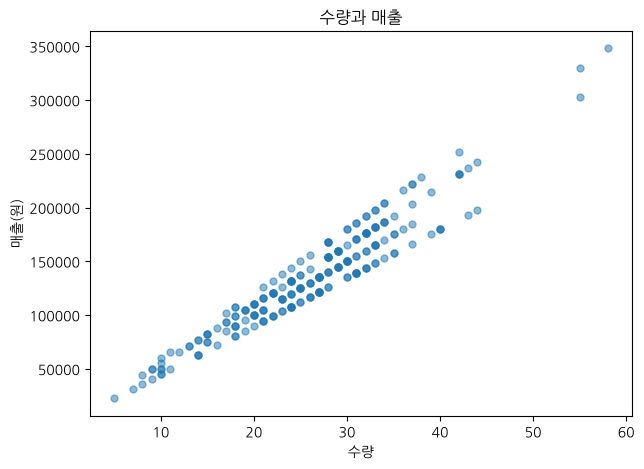

수량-매출 상관: 0.956


In [19]:
# TODO 1. 수량-매출 산점도 (일반 데이터)
일반.plot(kind="scatter", x="수량", y="매출", alpha=0.5, s=25, figsize=(7, 5),
         title="수량과 매출")
plt.xlabel("수량"); plt.ylabel("매출(원)")
plt.show()

# TODO 2. 상관계수
print("수량-매출 상관:", round(일반["수량"].corr(일반["매출"]), 3))

# 3. 답: 의미 없다. 매출은 0.2절에서 가격 × 수량으로 계산해 만든 열이라 수량이 늘면 매출이 늘어나는 건 계산 과정에서 이미 정해진 관계다(상관이 1이 안 되는 건 메뉴마다 가격이 달라서일 뿐). 데이터에서 발견한 패턴이 아니다.


---
## 6. 그룹 비교하기

6주차에 배운 `groupby()` 결과에 `.plot()` 을 이어 붙이면 됩니다.

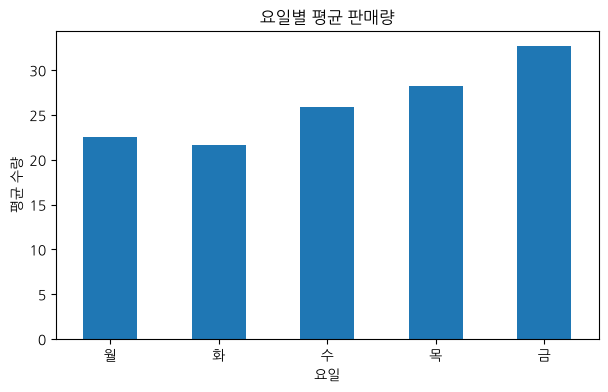

In [20]:
일반.groupby("요일")["수량"].mean().plot(
    kind="bar", title="요일별 평균 판매량", figsize=(7, 4))
plt.ylabel("평균 수량")
plt.xticks(rotation=0)       # 글자를 눕히지 않고 똑바로 세웁니다
plt.show()

월~금 순서가 그대로 지켜졌습니다. **0.2절에서 요일을 순서형으로 지정해 둔 덕분**입니다.

> **여러분 데이터에서 순서가 뒤죽박죽이라면** 0.2절로 돌아가서 그 열을 `pd.Categorical(..., ordered=True)` 로 지정하세요. 그래프를 그릴 때마다 고치는 것보다 한 번 지정해 두는 쪽이 훨씬 편합니다.

### 두 기준으로 나눠 보기

`groupby` 에 기준을 두 개 주고 `unstack()` 을 붙이면 **묶음 막대**가 됩니다.

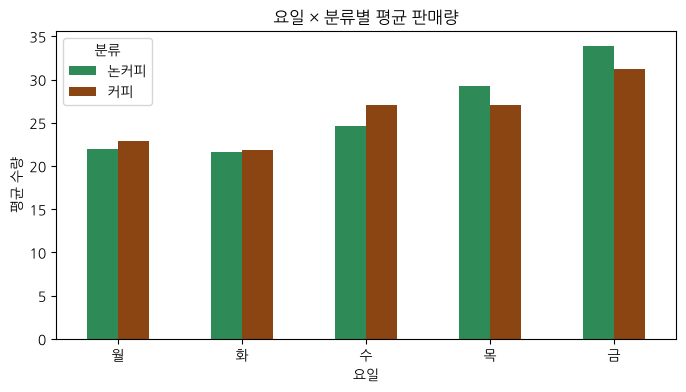

In [21]:
일반.groupby(["요일", "분류"])["수량"].mean().unstack().plot(
    kind="bar", figsize=(8, 4), title="요일 × 분류별 평균 판매량",
    color=["seagreen", "saddlebrown"])          # 5절과 같은 색으로 맞춥니다
plt.ylabel("평균 수량")
plt.xticks(rotation=0)
plt.show()

`unstack()` 은 **안쪽 그룹을 열로 펼치는** 기능입니다. 결과가 표 모양이 되면서 막대가 색깔별로 나뉩니다.

`color=` 로 5절 산점도와 **같은 색을 지정**했습니다. 보고서에서 같은 대상은 계속 같은 색으로 쓰는 게 좋습니다. 그림마다 색이 바뀌면 읽는 사람이 매번 범례를 다시 확인해야 합니다.

이 한 장에서 두 가지가 같이 보입니다. 요일이 뒤로 갈수록 많이 팔리고, 수·목·금에는 논커피가 조금 더 많습니다.

### 그룹 비교에서 꼭 같이 볼 것

 **평균 막대만 보면 안 됩니다.**

In [22]:
print(일반.groupby("요일")["수량"].agg(["mean", "count", "std"]).round(1))

    mean  count  std
요일                  
월   22.5     48  8.1
화   21.7     48  8.8
수   25.9     48  6.0
목   28.2     48  6.2
금   32.7     48  8.8


`count` 가 요일당 40여 건입니다. `std`(표준편차)도 10 안팎으로 작지 않습니다.

**막대 높이의 차이가 이 퍼짐보다 작다면, 그 차이를 두고 단정하기 어렵습니다.** 막대그래프는 평균만 보여주기 때문에 이 정보가 숨습니다. 4절의 박스플롯이 더 정직한 그림인 이유입니다.

### ⏸ 멈추고 직접 해보세요 (4)

1. `일반` 데이터로 **매장별 평균 평점**을 막대그래프로 그리세요
2. 같은 비교를 **박스플롯**으로도 그리세요
3. 두 그림을 비교하면 **어느 쪽이 더 정확한가요?** 주석에 한 줄 적어보세요

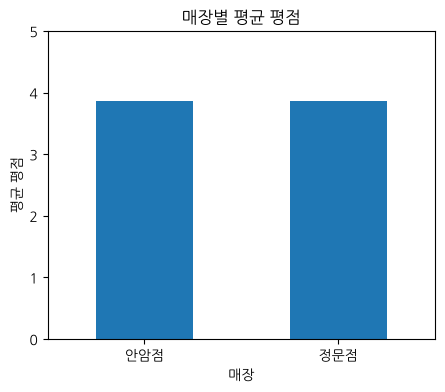

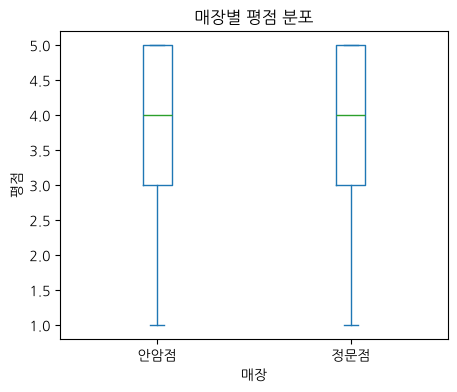

In [23]:
# TODO 1. 매장별 평균 평점 막대그래프 (y축은 0부터)
일반.groupby("매장")["평점"].mean().plot(kind="bar", title="매장별 평균 평점", figsize=(5, 4))
plt.ylim(0, 5)
plt.ylabel("평균 평점")
plt.xticks(rotation=0)
plt.show()

# TODO 2. 매장별 평점 박스플롯
일반.plot(kind="box", column="평점", by="매장", figsize=(5, 4))
plt.suptitle("")
plt.title("매장별 평점 분포")
plt.xlabel("매장")
plt.ylabel("평점")
plt.show()

# 3. 답: 평균 막대는 두 매장의 평균(3.86, 3.87)이 거의 같다는 것만 보여주고, 박스플롯은 퍼짐까지 보여줘서 더 정직한 쪽이다. 다만 평점은 1~5 정수라 상자가 정수 값에 붙어 납작하게 나오므로, 세밀한 비교가 필요하면 value_counts() 비율이 더 낫다.


---
## 7. 시간에 따라 보기

날짜가 있는 데이터는 **선그래프**로 흐름을 봅니다.

날짜별로 묶어서 합계를 내고 그립니다.

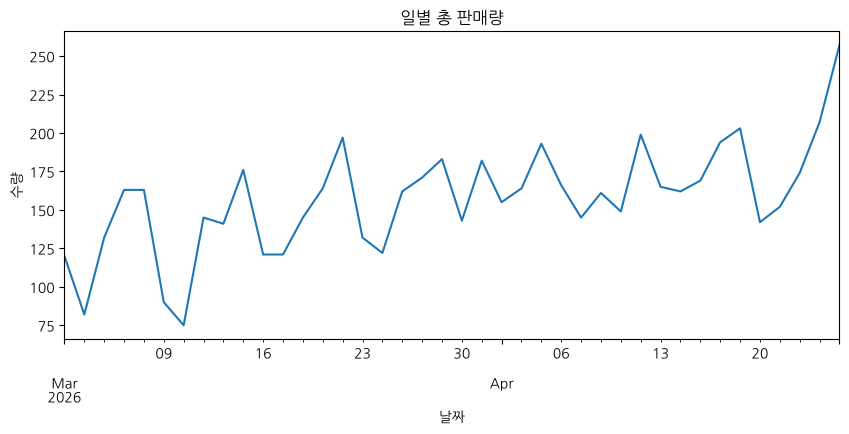

In [24]:
일별 = 일반.groupby("날짜")["수량"].sum()

일별.plot(kind="line", figsize=(10, 4), title="일별 총 판매량")
plt.xlabel("날짜"); plt.ylabel("수량")
plt.show()

**들쭉날쭉해서 읽기 어렵습니다.** 올라가는 것 같기도 한데 확신이 안 섭니다.

시계열 데이터의 흔한 문제입니다. 하루하루의 변동(요일 효과, 날씨, 우연)이 커서 **전체 흐름을 파악하기 어렵습니다.**

### 이동평균으로 부드럽게 만들기

**이동평균**은 "최근 며칠의 평균"으로 선을 다시 그리는 방법입니다. 하루치 변동이 평균에 섞이면서 추세만 남습니다.

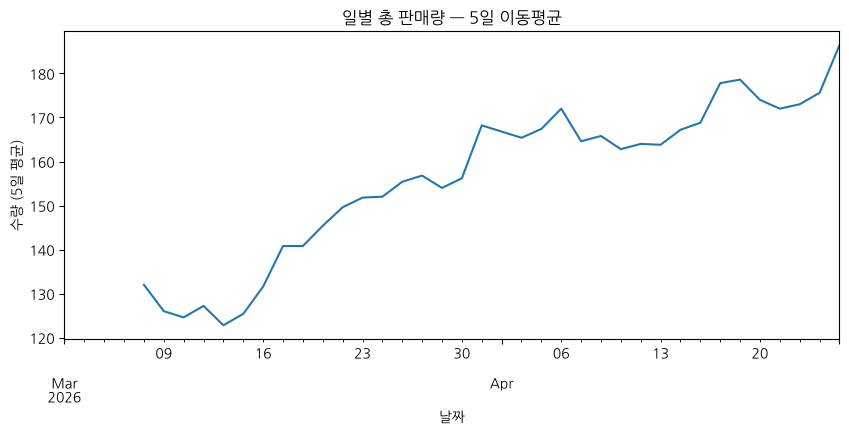

In [25]:
일별.rolling(5).mean().plot(kind="line", figsize=(10, 4),
                            title="일별 총 판매량 — 5일 이동평균")
plt.xlabel("날짜"); plt.ylabel("수량 (5일 평균)")
plt.show()

훨씬 명확해졌습니다. **오른쪽으로 갈수록 올라가는 추세**가 보입니다.

`rolling(5)` 는 "5일씩 묶어서"라는 뜻이고, 거기에 `.mean()` 을 붙여 평균을 냅니다. 평일 기준 5일이면 **한 주**입니다. 그래서 요일 효과가 상쇄됩니다.

> **왼쪽 끝이 비어 있는 이유**: 첫 4일은 5일치가 모이지 않아 평균을 낼 수 없습니다. 정상입니다.
>
> **며칠로 묶을지는 선택입니다.** 짧게 잡으면 들쭉날쭉하고, 길게 잡으면 부드럽지만 변화를 늦게 반영합니다. 3.1절의 `bins` 와 같은 성격의 선택이고, **보고서에 며칠로 묶었는지 밝혀야** 합니다.

### 두 선을 겹쳐 비교하기

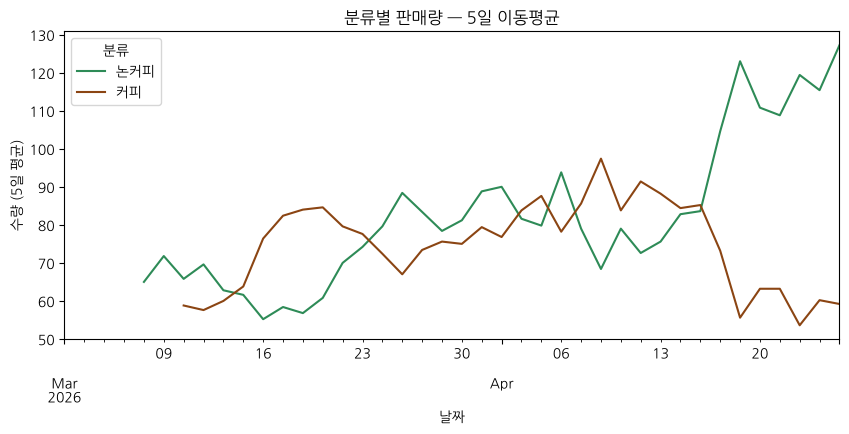

In [26]:
일별분류 = 일반.groupby(["날짜", "분류"])["수량"].sum().unstack()

일별분류.rolling(5).mean().plot(figsize=(10, 4),
                               title="분류별 판매량 — 5일 이동평균",
                               color=["seagreen", "saddlebrown"])
plt.xlabel("날짜"); plt.ylabel("수량 (5일 평균)")
plt.show()

논커피가 뚜렷하게 올라가고, 커피는 평평하거나 살짝 내려갑니다. 5절 산점도에서 본 것과 같은 이야기입니다.

**같은 사실을 다른 그림으로 확인하는 것**은 좋은 습관입니다. 한 그림에서만 보이는 패턴은 우연일 수 있기 때문입니다.

> ### 날짜 그래프를 그린 뒤에는 한 줄 더
>
> 날짜를 가로축으로 쓴 그래프를 그리고 나면, 그 다음에 **막대그래프를 그릴 때 오류가 나는** 경우가 있습니다.
>
> ```
> AttributeError: 'Index' object has no attribute 'freq'
> ```
>
> matplotlib이 날짜 축 설정을 붙들고 있어서 생기는 현상입니다. 아래 한 줄로 **그림판을 정리**하면 해결됩니다.

In [27]:
plt.close("all")      # 그림판 정리 — 날짜 그래프 다음에 한 번 실행하세요
print("정리 완료")

정리 완료


---
## 8. 그래프는 거짓말을 한다

같은 데이터로 **정반대 인상을 주는 그래프**를 만들 수 있습니다. 직접 만들어 봅시다.

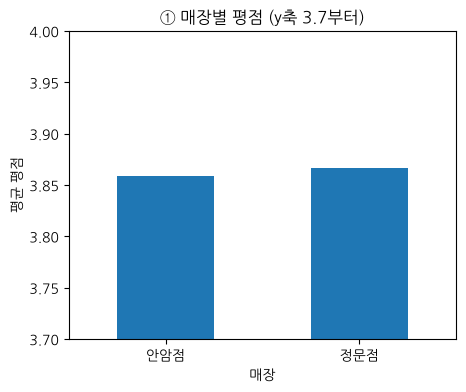

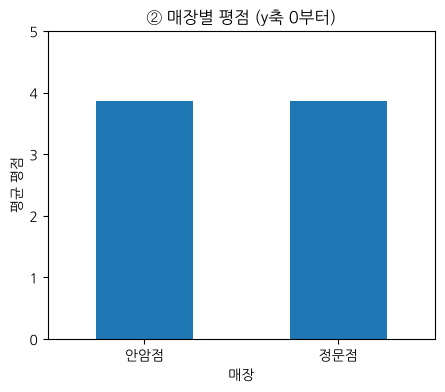

In [28]:
평균 = 일반.groupby("매장")["평점"].mean()

# ① y축을 잘라낸 그래프
평균.plot(kind="bar", title="① 매장별 평점 (y축 3.7부터)", figsize=(5, 4))
plt.ylim(3.7, 4.0)
plt.ylabel("평균 평점"); plt.xticks(rotation=0)
plt.show()

# ② y축을 0부터 시작한 그래프
평균.plot(kind="bar", title="② 매장별 평점 (y축 0부터)", figsize=(5, 4))
plt.ylim(0, 5)
plt.ylabel("평균 평점"); plt.xticks(rotation=0)
plt.show()

**①에서는 큰 차이처럼 보이고, ②에서는 거의 차이가 없어 보입니다. 같은 숫자입니다.**

`plt.ylim()` 으로 세로축 범위를 바꿨을 뿐입니다.

### 흔한 착시들

| 착시를 일으키는 수법 | 효과 |
|---|---|
| y축을 0이 아닌 곳에서 시작 | 작은 차이를 크게 보이게 |
| y축 범위를 지나치게 넓게 | 실제 차이를 묻어버리게 |
| 기간을 유리한 구간만 잘라 보여주기 | 추세를 반대로 보이게 |
| 3차원 입체 그래프 | 원근 때문에 크기 비교가 왜곡됨 |
| 막대 대신 그림 크기로 표현 | 넓이가 제곱으로 커져 과장됨 |

> ###  어느 쪽이 "올바른" 그래프일까요
>
> **막대그래프는 y축을 0부터 시작하는 것이 원칙입니다.** 막대의 길이로 크기를 비교하는 그림이기 때문입니다. 0에서 시작하지 않으면 길이 비율이 실제 값의 비율과 달라집니다.
>
> 다만 선그래프는 다릅니다. 체온이나 주가처럼 **변화를 보는 그림**에서는 0부터 그리면 아무것도 안 보입니다.
>
> 핵심은 규칙 암기가 아닙니다. **내가 축을 어떻게 잡았는지 스스로 알고 있는 것**, 그리고 **남의 그래프를 볼 때 축부터 확인하는 것**입니다.
>
> 뉴스나 보고서의 그래프를 볼 때 **세로축이 0에서 시작하는지** 먼저 보세요.

---
## 9. 본 것을 글로 옮기기

**다음 주 중간고사 대체 과제에서 중요한 것은 그래프보다는 글입니다.**

### 그래프 한 장에 문장 세 개

그래프를 넣을 때마다 세 가지를 씁니다.

| 문장 | 내용 |
|---|---|
| **무엇을 그렸나** | 어떤 데이터를 어떤 기준으로 |
| **무엇이 보이나** | 그림에서 읽히는 것 (사실만) |
| **무엇을 말할 수 없나** | 이 그림으로는 알 수 없는 것 |

세 번째가 가장 중요합니다.

### 나쁜 예

> 기온과 논커피 판매량의 산점도를 그렸다. 날씨가 더워지면 사람들이 시원한 음료를 찾기 때문에 논커피 판매가 늘어난다. 따라서 여름에는 논커피 재고를 늘려야 한다.

문제가 셋입니다. 그래프에서 **읽은 것**과 본인의 **추측**이 섞여 있습니다. 기온이 원인이라고 **단정**했습니다. 그리고 8주치 평일 데이터로 **여름 전체**를 설명하고 있습니다.

### 좋은 예

> 기온(가로축)과 일별 논커피 판매량(세로축)의 산점도를 그렸다 **(무엇을 그렸나)**.
>
> 기온이 높은 날일수록 논커피 판매량이 많은 경향이 뚜렷하게 나타났다. 상관계수는 0.87이었다. 같은 기간 커피는 이런 경향이 보이지 않았다 **(무엇이 보이나)**.
>
> 다만 이 관계가 기온 때문이라고 단정할 수는 없다. 관측 기간인 3~4월은 개강과 중간고사가 겹쳐 캠퍼스 유동인구 자체가 달라졌을 수 있고, 그 기간에 신메뉴나 행사가 있었는지는 이 데이터에 기록되어 있지 않다. 또한 평일 8주치 기록이므로 주말이나 다른 계절에도 같은 패턴이 나타날지는 알 수 없다 **(무엇을 말할 수 없나)**.

###  표현

| 쓰세요 | 쓰지 마세요 |
|---|---|
| ~한 경향이 나타났다 | ~가 원인이다 |
| ~와 함께 증가했다 | ~가 ~를 증가시켰다 |
| 이 기간/이 데이터에서는 | 일반적으로, 항상 |
| 차이가 보인다 | 차이가 있다 (검정 없이) |
| 추정된다, ~일 수 있다 | ~임이 증명되었다 |



### ⏸ 직접 해보세요 (5)

4절에서 그린 **요일별 수량 박스플롯**에 대해 위의 세 문장을 써보세요.

그래프를 다시 그릴 필요는 없습니다. 글만 쓰면 됩니다.

In [29]:
# ▼ 무엇을 그렸나:
# 단체 주문 2건(수량 100 이상)을 뺀 일반 판매 240건을 요일(월~금)별 수량 박스플롯으로 그렸다.

# ▼ 무엇이 보이나:
# 중앙값이 월 23, 화 20, 수 26.5, 목 28, 금 32로, 수~금 쪽이 높은 경향이 나타났다. 월요일과 화요일은 비슷하고 오히려 화요일이 더 낮다.
# 다만 월·화, 목·금처럼 인접한 요일끼리는 상자가 겹치는 구간이 있어 모든 요일 사이의 차이를 단정하기는 어렵다.

# ▼ 무엇을 말할 수 없나:
# 이 그림만으로는 요일이 원인인지 알 수 없다. 요일마다 수업 시간표나 행사 같은 다른 요인이 다를 수 있지만 이 데이터에는 기록되어 있지 않다.
# 한 상자에 같은 날의 여러 매장·메뉴 기록이 함께 들어 있어 메뉴 구성의 영향도 분리되지 않는다.
# 단체 주문 2건이 모두 금요일이었고 이를 뺐으므로 이 그림은 금요일 전체 판매를 나타내지 않는다.
# 또한 8주치 평일 기록이므로 주말이나 다른 학기에도 같은 패턴이 나타날지는 알 수 없다.


### 점검: 막힌 부분이 있다면 어디인지 알려주세요.

- [ ] `.plot()` 에 `kind=` 를 넣는 구조
- [ ] 어떤 그래프를 골라야 할지 (2절 표)
- [ ] 히스토그램과 막대그래프의 차이
- [ ] 박스플롯 읽는 법
- [ ] `ax=` 로 겹쳐 그리기
- [ ] `groupby().plot()` 이어 붙이기
- [ ] `unstack()`
- [ ] 상관계수의 의미
- [ ] 세 문장으로 글 쓰기
- [ ] 기타:

> **아래 코드 셀에 답을 적어주세요.**

In [30]:
# ▼ 가장 헷갈린 부분은?
# 답:


# ▼ 내 데이터에 적용해 보려니 막히는 점이 있나요?
# 답:


---
## 11. 다음 주 중간 프로젝트 안내

**다음 주(8주차)는 수업이 없습니다.** 대신 중간고사 대체 리포트를 제출합니다.

### 한 줄 요약

> **여러분이 고른 데이터로 EDA를 하고, 그 과정과 결과를 보고서로 쓰는 것**입니다.

지난 네 주 동안 한 것을 자기 데이터로 한 번 더 하는 셈입니다.

| 주차 | 배운 것 | 보고서에서 |
|---|---|---|
| 5주차 1절 | 데이터 설명서 | **1. 데이터 소개** |
| 6주차 | 정제 (빈칸·중복·표기·자료형) | **2. 정제 과정** |
| 7주차 (오늘) | 그래프와 EDA | **3. 탐색** |
| 7주차 9절 | 세 문장 쓰기 | **4. 발견 / 5. 한계** |

### 제출물

1. **보고서** (PDF로 제출)
2. **Colab 노트북** (.ipynb - 실행 결과가 남아 있어야 합니다)

### 마감

**2026년 10월 29일(목) 23:59**, LMS 제출




---

수고하셨습니다. 질문은 LMS Q&A 게시판에 올려주세요.